# PROJEK JARINGAN SYARAF TIRUAN (JST)
## Prediksi Intensitas Kebakaran Hutan (Fire Radiative Power / FRP) di Kalimantan Menggunakan Data Riil Satelit NASA FIRMS (VIIRS 375m)

### Konteks & Latar Belakang Masalah
Kebakaran hutan dan lahan (karhutla) di Kalimantan menimbulkan dampak ekologis, kerugian ekonomi, gangguan kesehatan lintas wilayah, serta ancaman keselamatan bagi personel pemadaman di lapangan (seperti insiden helikopter water-bombing di Seruyan, Kalteng).

Satelit **Suomi-NPP** dengan sensor **VIIRS (Visible Infrared Imaging Radiometer Suite)** mendeteksi anomali termal aktif. Energi termal yang dilepaskan dikuantifikasi sebagai **Fire Radiative Power (FRP)** dalam MegaWatt (MW), indikator utama keganasan kobaran api.

Model yang dibangun: **Jaringan Syaraf Tiruan (JST) - Multilayer Perceptron (MLP)** berbasis **PyTorch** (CUDA bila tersedia).

### Ringkasan Revisi (hasil audit)
Versi sebelumnya melaporkan R² 0,53 (JST) dan 0,59 (XGBoost) dengan **split acak**. Audit menemukan empat masalah yang diperbaiki di notebook ini:

| # | Masalah | Perbaikan |
|---|---|---|
| 1 | Split acak membocorkan piksel kembar: 29,6% titik uji punya tetangga di data latih (overpass sama) dengan FRP **identik** | Split berkelompok per **overpass × sel 0,5°** (piksel kembar tinggal 0,4%), plus uji GroupKFold, *forward-chaining* per hari, dan uji waktu |
| 2 | Piksel I4 terlipat (208 K) dibaca sebagai api dingin, sehingga JST memprediksi sampai ribuan MW; kalibrasi isotonic menutupinya | Flag `ti4_folded`/`ti4_saturated`, 208 K diset ke 367 K, keluaran log dibatasi rentang data latih |
| 3 | Kerapatan hotspot per tanggal UTC ikut memakai deteksi overpass berikutnya (±12 jam ke depan); `day_idx` tidak berlaku untuk tanggal baru | Kerapatan dihitung **per overpass**; `day_idx` dihapus dari fitur |
| 4 | Ambang tetap 20 MW membuat recall CRITICAL rendah | **Ambang alarm dituning di data validasi** (target recall 70%) |

### Hasil tanpa kebocoran (data uji berkelompok, 6.729 sampel)
| Model | MSE | RMSE (MW) | MAE (MW) | R² |
|---|---|---|---|---|
| JST + kalibrasi isotonic | 133,10 | 11,54 | 4,12 | 0,295 |
| XGBoost (tweedie) | 130,45 | 11,42 | 4,05 | 0,309 |
| **Ensemble JST 0,65 + XGB 0,35 (model final)** | **130,37** | **11,42** | **4,05** | **0,309** |

Validasi silang XGBoost (lebih stabil daripada satu holdout): R² **0,52** bila split acak (bocor) → **0,39** GroupKFold → **0,35** *forward-chaining* per hari. Uji waktu JST (latih hari 0–9, uji hari 12–14): R² **0,37**. Angka ini lebih rendah dari versi sebelumnya bukan karena modelnya memburuk, tetapi karena kebocoran dihilangkan.

In [1]:
# 1. Import Library Utama & Konfigurasi Komputasi
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, KFold
from sklearn.neighbors import BallTree
from sklearn.preprocessing import StandardScaler
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version  : {torch.__version__}')
print(f'Komputasi Device : {device.type.upper()}')
if device.type == 'cuda':
    print(f'Nama GPU         : {torch.cuda.get_device_name(0)}')
    print(f'Alokasi Memori   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB')

PyTorch Version  : 2.15.0+cu132
Komputasi Device : CPU


### 2. Memuat Dataset Riil NASA FIRMS (Kalimantan)

Dataset bersih berisi 35.826 titik api. Kolom `acq_time`, `acq_date`, dan `daynight` diambil dari file mentah dan diselaraskan baris demi baris (satu baris FRP 529,28 MW telah dibuang pada tahap *cleaning*).

Setiap baris juga diberi ID **overpass** (tanggal UTC + siang/malam). Satu overpass = satu lintasan satelit; seluruh deteksi dalam satu overpass tersedia pada saat yang sama, sedangkan overpass berikutnya baru ada ±12 jam kemudian.

In [2]:
raw = pd.read_csv('nasa_viirs_kalimantan_raw.csv')
cleaned = pd.read_csv('data_karhutla_kalimantan_cleaned.csv')

raw = raw[raw['frp'] < 500].reset_index(drop=True)
assert len(raw) == len(cleaned), 'panjang data mentah dan bersih tidak sama'
assert np.allclose(raw['frp'].values, cleaned['frp'].values), 'urutan baris tidak selaras'

df = cleaned.copy()
df['acq_time'] = raw['acq_time'].values          # UTC, format HHMM
df['acq_date'] = pd.to_datetime(raw['acq_date'].values)
df['day_idx'] = (df['acq_date'] - df['acq_date'].min()).dt.days
df['daynight'] = raw['daynight'].values
df['overpass'] = df['acq_date'].dt.strftime('%Y-%m-%d') + '_' + df['daynight']

print(f'Ukuran dataset: {df.shape[0]:,} baris data dan {df.shape[1]} kolom.')
print(f'Periode data  : {df["acq_date"].min().date()} s/d {df["acq_date"].max().date()} '
      f'({df["day_idx"].nunique()} hari, {df["overpass"].nunique()} overpass)')
df.head()

Ukuran dataset: 35,826 baris data dan 14 kolom.
Periode data  : 2026-10-18 s/d 2026-11-01 (15 hari, 29 overpass)


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,frp,acq_time,acq_date,day_idx,daynight,overpass
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,3.33,622,2026-10-18,0,D,2026-10-18_D
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,8.11,622,2026-10-18,0,D,2026-10-18_D
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,3.33,622,2026-10-18,0,D,2026-10-18_D
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,5.56,622,2026-10-18,0,D,2026-10-18_D
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,3.25,622,2026-10-18,0,D,2026-10-18_D


### 3. Eksplorasi Data, Korelasi Fitur, & Distribusi Target

,count,mean,std,min,25%,50%,75%,max
latitude,35826.0,-2.372889,1.013729,-4.17222,-2.946455,-2.685350,-2.103135,4.46876
longitude,35826.0,113.544240,1.777740,109.28479,112.151180,113.613165,114.490482,119.49319
bright_ti4,35826.0,326.947861,18.402483,208.00000,309.330000,330.140000,340.890000,367.00000
scan,35826.0,0.452620,0.078329,0.32000,0.400000,0.430000,0.490000,0.80000
track,35826.0,0.460747,0.111197,0.36000,0.380000,0.400000,0.540000,0.78000
bright_ti5,35826.0,292.515541,9.175385,241.17000,289.310000,294.200000,297.460000,359.34000
is_day,35826.0,0.404901,0.490880,0.00000,0.000000,0.000000,1.000000,1.00000
confidence_score,35826.0,2.005750,0.244568,1.00000,2.000000,2.000000,2.000000,3.00000
frp,35826.0,7.360030,12.354437,0.15000,1.840000,3.690000,7.880000,319.51000


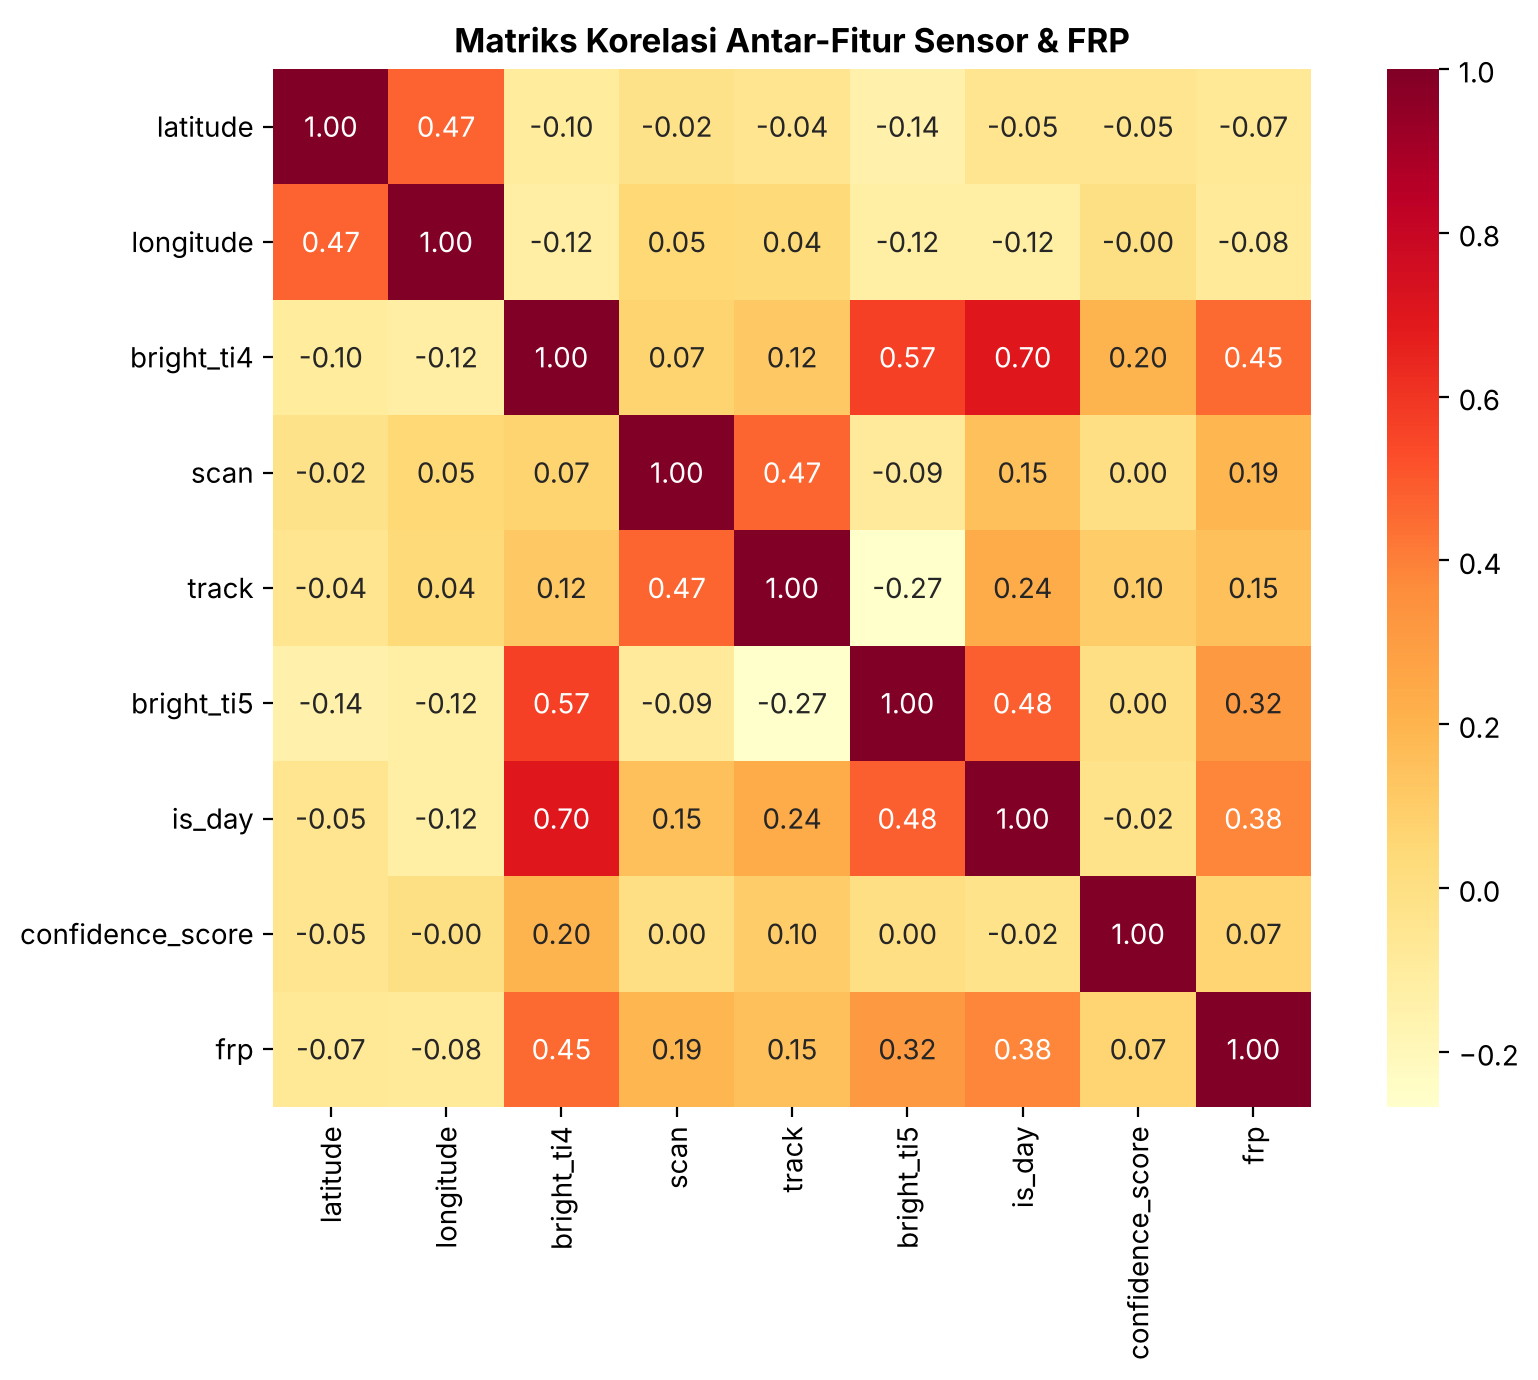

In [3]:
SENSOR_COLS = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
               'bright_ti5', 'is_day', 'confidence_score', 'frp']

display(df[SENSOR_COLS].describe().T)

plt.figure(figsize=(9, 7))
sns.heatmap(df[SENSOR_COLS].corr(), annot=True, fmt='.2f', cmap='YlOrRd',
            cbar=True, square=True)
plt.title('Matriks Korelasi Antar-Fitur Sensor & FRP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('matriks_korelasi_fitur.png', dpi=300, bbox_inches='tight')
plt.show()

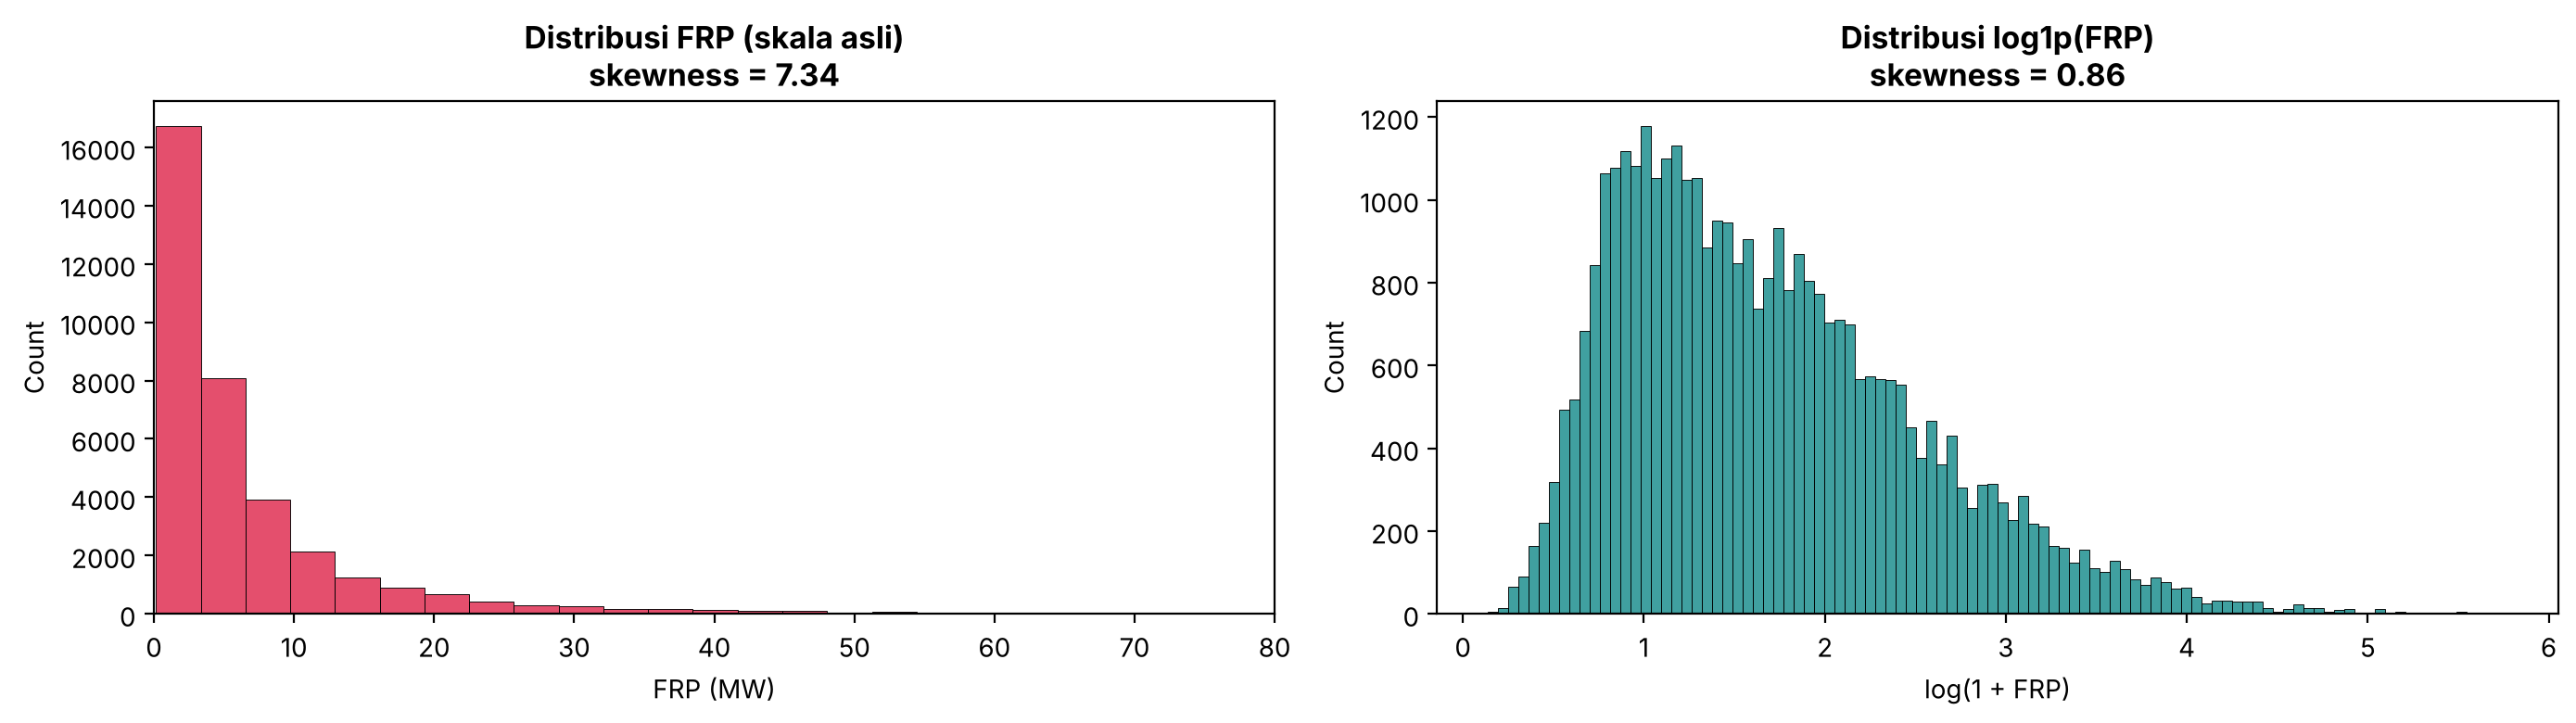

Median FRP : 3.69 MW
Mean FRP   : 7.36 MW
Maks FRP   : 319.51 MW
Sampel FRP >= 20 MW (CRITICAL): 2,676 (7.47%)


In [4]:
# Bukti skewness target: skala asli vs log1p
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df['frp'], bins=100, ax=axes[0], color='crimson')
axes[0].set_xlim(0, 80)
axes[0].set_title(f'Distribusi FRP (skala asli)\nskewness = {df["frp"].skew():.2f}', fontweight='bold')
axes[0].set_xlabel('FRP (MW)')

sns.histplot(np.log1p(df['frp']), bins=100, ax=axes[1], color='teal')
axes[1].set_title(f'Distribusi log1p(FRP)\nskewness = {np.log1p(df["frp"]).skew():.2f}', fontweight='bold')
axes[1].set_xlabel('log(1 + FRP)')
plt.tight_layout()
plt.show()

print(f'Median FRP : {df["frp"].median():.2f} MW')
print(f'Mean FRP   : {df["frp"].mean():.2f} MW')
print(f'Maks FRP   : {df["frp"].max():.2f} MW')
print(f'Sampel FRP >= 20 MW (CRITICAL): {(df["frp"] >= 20).sum():,} '
      f'({(df["frp"] >= 20).mean() * 100:.2f}%)')

### 3b. Kualitas Data Sensor: Saturasi & *Fold-over* Kanal I4

Menurut dokumentasi produk VIIRS 375 m, nilai `bright_ti4` berada pada rentang **208–367 K**. Piksel api yang terlalu panas diberi nilai saturasi **367 K**, dan pada api yang sangat ekstrem nilai digitalnya **terlipat (*fold-over*)** sehingga tampak bersuhu sangat rendah (208 K). Piksel 208 K karenanya **bukan api dingin**, melainkan api yang melampaui batas ukur sensor.

Selain itu, FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak tersedia di CSV FIRMS, sehingga pada piksel jenuh fitur suhu I4 tidak lagi membawa informasi intensitas. Ini batas informasi yang menjelaskan kenapa kelas CRITICAL sulit diprediksi.

In [5]:
folded = df['bright_ti4'] <= 208.0
saturated = df['bright_ti4'] >= 367.0
print(f'Piksel I4 jenuh (367 K)   : {saturated.sum():,} ({saturated.mean() * 100:.2f}%) | '
      f'median FRP {df.loc[saturated, "frp"].median():.2f} MW')
print(f'Piksel I4 normal          : {(~saturated & ~folded).sum():,} | '
      f'median FRP {df.loc[~saturated & ~folded, "frp"].median():.2f} MW')
print(f'Piksel I4 terlipat (208 K): {folded.sum()} | FRP {df.loc[folded, "frp"].min():.2f}'
      f'–{df.loc[folded, "frp"].max():.2f} MW | confidence {sorted(df.loc[folded, "confidence_score"].unique())}')
display(df.loc[folded, ['latitude', 'longitude', 'bright_ti4', 'bright_ti5',
                        'confidence_score', 'frp', 'overpass']])

# Korelasi Pearson meremehkan hubungan monotonik pada target yang sangat menceng
display(pd.DataFrame({'Pearson': df[SENSOR_COLS].corr()['frp'],
                      'Spearman': df[SENSOR_COLS].corr(method='spearman')['frp']})
        .drop('frp').round(3))

Piksel I4 jenuh (367 K)   : 1,185 (3.31%) | median FRP 16.42 MW
Piksel I4 normal          : 34,631 | median FRP 3.51 MW
Piksel I4 terlipat (208 K): 10 | FRP 48.30–276.85 MW | confidence [np.int64(1)]


,latitude,longitude,bright_ti4,bright_ti5,confidence_score,frp,overpass
14233,-3.75215,116.18639,208.0,303.39,1,276.85,2026-10-22_D
14243,-3.74565,116.18549,208.0,315.36,1,276.85,2026-10-22_D
14249,-3.73944,116.18182,208.0,294.43,1,98.47,2026-10-22_D
14632,-2.48189,114.41513,208.0,313.22,1,154.31,2026-10-22_D
15391,-3.18792,111.96381,208.0,308.42,1,48.30,2026-10-22_D
15616,-3.12363,111.86930,208.0,308.37,1,56.96,2026-10-22_D
15664,-3.11482,111.92310,208.0,307.26,1,65.18,2026-10-22_D
16583,-2.67684,113.37987,208.0,305.50,1,105.45,2026-10-22_D
17113,-2.68006,113.37845,208.0,298.23,1,71.99,2026-10-22_D
31924,0.19339,116.61574,208.0,310.92,1,104.94,2026-10-26_D


,Pearson,Spearman
latitude,-0.069,-0.160
longitude,-0.079,-0.133
bright_ti4,0.451,0.830
scan,0.192,0.225
track,0.152,0.206
bright_ti5,0.315,0.549
is_day,0.384,0.652
confidence_score,0.067,0.077


### 4. Preprocessing: Feature Engineering, Splitting, & Normalisasi

**Fitur sensor dasar (8)**: `latitude`, `longitude`, `bright_ti4`, `scan`, `track`, `bright_ti5`, `is_day`, `confidence_score`. Untuk piksel terlipat, `bright_ti4` diset ke 367 K (melampaui saturasi) sebelum fitur turunan dihitung.

**Flag kualitas I4 (2)**

| Fitur | Definisi | Alasan |
|---|---|---|
| `ti4_folded` | `bright_ti4 == 208 K` | Api ekstrem yang membuat nilai digital I4 terlipat |
| `ti4_saturated` | `bright_ti4 >= 367 K` atau terlipat | Suhu I4 tidak lagi mengukur intensitas |

**Fitur turunan termal & geometris (7)**

| Fitur | Rumus | Alasan |
|---|---|---|
| `delta_t` | `bright_ti4 - bright_ti5` | Kontras suhu api terhadap latar (proksi energi radiasi) |
| `pixel_area` | `scan * track` | Luas piksel; FRP adalah daya total per piksel, jadi piksel lebih luas → FRP lebih besar |
| `ti4_day` | `bright_ti4 * is_day` | Interaksi suhu–waktu |
| `ti4_ti5_ratio` | `bright_ti4 / bright_ti5` | Kontras relatif terhadap kondisi latar |
| `delta_t_day` | `delta_t * is_day` | Kontras termal terkoreksi siang/malam |
| `conf_high` | `confidence_score == 3` | One-hot keyakinan deteksi tinggi |
| `conf_nominal` | `confidence_score == 2` | One-hot keyakinan nominal |

**Fitur temporal (3)** — dari `acq_time` (UTC)

| Fitur | Alasan |
|---|---|
| `hour_frac` | Fraksi waktu akuisisi dalam sehari (siklus diurnal) |
| `hour_sin`, `hour_cos` | Encoding siklik agar jam 23:59 dan 00:01 berdekatan |

`day_idx` **tidak lagi dipakai sebagai fitur**: untuk tanggal baru nilainya selalu di luar rentang data latih.

**Fitur kerapatan hotspot (4)** — dihitung **per overpass** dari koordinat saja (tanpa target)

| Fitur | Alasan |
|---|---|
| `cell_density` | Jumlah hotspot di sel grid 0,5° pada overpass yang sama |
| `neigh_density` | Jumlah hotspot blok 3×3 sel (klaster kebakaran besar) |
| `overpass_total` | Total hotspot se-Kalimantan pada overpass tersebut |
| `neigh_density_norm` | Rasio klaster terhadap total overpass |

Versi sebelumnya menghitung kerapatan per tanggal UTC, sehingga titik api siang ikut "melihat" deteksi overpass malam ±12 jam kemudian (informasi masa depan). Per overpass, semua informasi sudah tersedia saat data satelit diterima.

**Total 24 fitur masukan.** Target dilatih sebagai `log1p(FRP)`; `StandardScaler` hanya di-*fit* pada data latih.

In [6]:
BASE_FEATURES = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track',
                 'bright_ti5', 'is_day', 'confidence_score']
TARGET = 'frp'
I4_FOLD_K, I4_SAT_K = 208.0, 367.0
GRID_DEG = 0.5

def fix_i4(frame):
    # Piksel terlipat (208 K) = api di atas batas ukur: tandai lalu set ke nilai saturasi.
    out = frame.copy()
    is_folded = frame['bright_ti4'] <= I4_FOLD_K
    out['ti4_folded'] = is_folded.astype(np.float32)
    out['ti4_saturated'] = (is_folded | (frame['bright_ti4'] >= I4_SAT_K)).astype(np.float32)
    out.loc[is_folded, 'bright_ti4'] = I4_SAT_K
    return out

def add_thermal_features(frame):
    out = frame.copy()
    out['delta_t'] = frame['bright_ti4'] - frame['bright_ti5']
    out['pixel_area'] = frame['scan'] * frame['track']
    out['ti4_day'] = frame['bright_ti4'] * frame['is_day']
    out['ti4_ti5_ratio'] = frame['bright_ti4'] / frame['bright_ti5']
    out['delta_t_day'] = out['delta_t'] * frame['is_day']
    out['conf_high'] = (frame['confidence_score'] == 3).astype(np.float32)
    out['conf_nominal'] = (frame['confidence_score'] == 2).astype(np.float32)
    return out

def add_temporal_features(frame):
    out = frame.copy()
    minutes = (frame['acq_time'] // 100) * 60 + (frame['acq_time'] % 100)
    out['hour_frac'] = minutes / 1440.0
    out['hour_sin'] = np.sin(2 * np.pi * out['hour_frac'])
    out['hour_cos'] = np.cos(2 * np.pi * out['hour_frac'])
    return out

def grid_cell(frame):
    return (np.floor(frame['latitude'] / GRID_DEG).astype(int).values,
            np.floor(frame['longitude'] / GRID_DEG).astype(int).values)

def build_density_tables(frame):
    # Kerapatan hotspot per (overpass, sel grid 0,5 derajat); hanya memakai koordinat & overpass.
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    keys = ['overpass', 'glat', 'glon']
    cell = g.groupby(keys).size().rename('cell_density').reset_index()

    frames = []
    for d_lat in (-1, 0, 1):
        for d_lon in (-1, 0, 1):
            tmp = cell.copy()
            tmp['glat'] = tmp['glat'] + d_lat
            tmp['glon'] = tmp['glon'] + d_lon
            frames.append(tmp)
    neigh = (pd.concat(frames).groupby(keys)['cell_density']
             .sum().rename('neigh_density').reset_index())
    total = g.groupby('overpass').size().rename('overpass_total').reset_index()
    return cell, neigh, total

def add_density_features(frame, tables):
    cell, neigh, total = tables
    keys = ['overpass', 'glat', 'glon']
    g = frame[['overpass', 'latitude', 'longitude']].copy()
    g['glat'], g['glon'] = grid_cell(g)
    g = (g.merge(cell, on=keys, how='left')
          .merge(neigh, on=keys, how='left')
          .merge(total, on='overpass', how='left'))
    cols = ['cell_density', 'neigh_density', 'overpass_total']
    g[cols] = g[cols].fillna(0)
    g['neigh_density_norm'] = (g['neigh_density'] / g['overpass_total'].replace(0, np.nan)).fillna(0)
    return g[DENSITY].reset_index(drop=True)

I4_FLAGS = ['ti4_folded', 'ti4_saturated']
THERMAL = ['delta_t', 'pixel_area', 'ti4_day', 'ti4_ti5_ratio',
           'delta_t_day', 'conf_high', 'conf_nominal']
TEMPORAL = ['hour_frac', 'hour_sin', 'hour_cos']
DENSITY = ['cell_density', 'neigh_density', 'overpass_total', 'neigh_density_norm']
FEATURES = BASE_FEATURES + I4_FLAGS + THERMAL + TEMPORAL + DENSITY

df_fe = add_temporal_features(add_thermal_features(fix_i4(df))).reset_index(drop=True)
density_tables = build_density_tables(df_fe)
df_fe = pd.concat([df_fe, add_density_features(df_fe, density_tables)], axis=1)

print(f'Jumlah fitur total: {len(FEATURES)}')
df_fe[FEATURES].head()

Jumlah fitur total: 24


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,ti4_folded,ti4_saturated,...,delta_t_day,conf_high,conf_nominal,hour_frac,hour_sin,hour_cos,cell_density,neigh_density,overpass_total,neigh_density_norm
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,0.0,0.0,...,32.24,0.0,1.0,0.265278,0.995396,-0.095846,407,741,3093,0.239573
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,0.0,1.0,...,59.90,1.0,0.0,0.265278,0.995396,-0.095846,407,741,3093,0.239573
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,0.0,0.0,...,27.95,0.0,0.0,0.265278,0.995396,-0.095846,407,741,3093,0.239573
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,0.0,0.0,...,28.90,0.0,1.0,0.265278,0.995396,-0.095846,407,741,3093,0.239573
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,0.0,0.0,...,39.03,0.0,1.0,0.265278,0.995396,-0.095846,407,741,3093,0.239573


#### Splitting berkelompok (tanpa kebocoran)

Satu kebakaran terdeteksi sebagai banyak piksel 375 m yang bersebelahan dalam satu overpass, dan karena FRP dihitung dari piksel M13 750 m, piksel tetangga sering memiliki **FRP yang persis sama**. Split acak menaruh piksel-piksel kembar ini di data latih dan data uji sekaligus, sehingga skor uji terlalu optimistis (dibuktikan di bagian 8c).

Karena itu data dibagi per **kelompok = overpass × sel grid 0,5°**: seluruh piksel dalam satu kelompok selalu berada di sisi yang sama (latih, validasi, atau uji). Proporsi ±64% latih, 16% validasi, 20% uji.

In [7]:
X = df_fe[FEATURES].values.astype(np.float32)
y = df_fe[TARGET].values.astype(np.float64)

glat, glon = grid_cell(df_fe)
groups = (df_fe['overpass'] + '_' + pd.Series(glat).astype(str) + '_' + pd.Series(glon).astype(str)).values

def grouped_split(idx, test_size, seed=SEED):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(idx, groups=groups[idx]))
    return idx[a], idx[b]

idx_all = np.arange(len(df_fe))
idx_train_full, idx_test = grouped_split(idx_all, test_size=0.2)
idx_train, idx_val = grouped_split(idx_train_full, test_size=0.2)
assert not (set(groups[idx_train]) & set(groups[idx_test])), 'kelompok bocor ke data uji'
assert not (set(groups[idx_train]) & set(groups[idx_val])), 'kelompok bocor ke data validasi'

X_train, X_val, X_test = X[idx_train], X[idx_val], X[idx_test]
y_train, y_val, y_test = y[idx_train], y[idx_val], y[idx_test]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f'Jumlah kelompok (overpass x sel 0,5°): {len(np.unique(groups)):,}')
print(f'Jumlah Data Latih (Train) : {len(X_train):,} sampel')
print(f'Jumlah Data Validasi (Val): {len(X_val):,} sampel')
print(f'Jumlah Data Uji (Test)    : {len(X_test):,} sampel')
print(f'Bentuk X_train            : {X_train_scaled.shape}')

Jumlah kelompok (overpass x sel 0,5°): 1,514
Jumlah Data Latih (Train) : 24,228 sampel
Jumlah Data Validasi (Val): 4,869 sampel
Jumlah Data Uji (Test)    : 6,729 sampel
Bentuk X_train            : (24228, 24)


### 5. Arsitektur Jaringan Syaraf Tiruan (Deep Multilayer Perceptron)

1. **Input Layer**: 24 neuron.
2. **Hidden Layer 1**: 256 neuron → `BatchNorm1d` → `GELU` → Dropout `0.2`.
3. **Hidden Layer 2**: 128 neuron → `BatchNorm1d` → `GELU` → Dropout `0.1`.
4. **Hidden Layer 3**: 64 neuron → `BatchNorm1d` → `GELU` → Dropout `0.05`.
5. **Output Layer**: 1 neuron `Linear` → memprediksi `log1p(FRP)`.

`BatchNorm` menstabilkan skala fitur kerapatan hotspot yang sangat menceng, sedangkan `GELU` memberi gradien lebih halus daripada `ReLU` pada data tabular.

In [8]:
class KarhutlaJST(nn.Module):
    def __init__(self, input_dim, hidden=(256, 128, 64), drop=(0.2, 0.1, 0.05)):
        super(KarhutlaJST, self).__init__()
        layers, prev = [], input_dim
        for i, h in enumerate(hidden):
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.GELU()]
            if i < len(drop):
                layers.append(nn.Dropout(drop[i]))
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal Parameter JST yang Dilatih: {total_params:,} bobot & bias.')

KarhutlaJST(
  (network): Sequential(
    (0): Linear(in_features=24, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): GELU(approximate='none')
    (11): Dropout(p=0.05, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)

Total Parameter JST yang Dilatih: 48,513 bobot & bias.


### 6. Pelatihan Model: Backpropagation, LR Scheduler, & Early Stopping

- **Loss**: MSE pada ruang `log1p(FRP)`.
- **Optimizer**: AdamW (`lr = 0.001`, `weight_decay = 1e-4`), batch size 128.
- **Scheduler**: `ReduceLROnPlateau` (faktor 0.5, patience 10).
- **Early stopping**: berhenti bila val loss tidak membaik 30 epoch; bobot terbaik dipulihkan.
- **Epoch maksimum**: 300.

Pelatihan dibungkus dalam fungsi `train_jst` agar bisa dipakai ulang pada uji ketahanan (bagian 8c).

In [9]:
def train_jst(X_tr_scaled, y_tr, X_va_scaled, y_va, epochs_max=300, patience=30, verbose=True):
    set_seed(SEED)
    net = KarhutlaJST(input_dim=X_tr_scaled.shape[1]).to(device)
    train_ds = TensorDataset(torch.tensor(X_tr_scaled, dtype=torch.float32),
                             torch.tensor(np.log1p(y_tr), dtype=torch.float32).unsqueeze(1))
    val_ds = TensorDataset(torch.tensor(X_va_scaled, dtype=torch.float32),
                           torch.tensor(np.log1p(y_va), dtype=torch.float32).unsqueeze(1))
    train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=512, shuffle=False)

    criterion = nn.MSELoss()
    optimizer = optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10)
    hist = {'train_loss': [], 'val_loss': []}
    best_val, best_state, bad_epochs = float('inf'), None, 0

    for epoch in range(1, epochs_max + 1):
        net.train()
        running = 0.0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            loss = criterion(net(batch_x), batch_y)
            loss.backward()
            optimizer.step()
            running += loss.item() * batch_x.size(0)
        epoch_train_loss = running / len(train_ds)

        net.eval()
        running = 0.0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                running += criterion(net(batch_x), batch_y).item() * batch_x.size(0)
        epoch_val_loss = running / len(val_ds)

        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step(epoch_val_loss)
        hist['train_loss'].append(epoch_train_loss)
        hist['val_loss'].append(epoch_val_loss)

        if epoch_val_loss < best_val - 1e-6:
            best_val, bad_epochs = epoch_val_loss, 0
            best_state = {k: v.detach().clone() for k, v in net.state_dict().items()}
        else:
            bad_epochs += 1

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f'Epoch [{epoch:03d}/{epochs_max}] | Train MSE (log): {epoch_train_loss:.5f} | '
                  f'Val MSE (log): {epoch_val_loss:.5f} | LR: {current_lr:.2e} | '
                  f'no-improve: {bad_epochs}/{patience}')
        if bad_epochs >= patience:
            if verbose:
                print(f'\nEarly stopping pada epoch {epoch} (val loss terbaik {best_val:.5f}).')
            break

    net.load_state_dict(best_state)
    return net, hist

print('Memulai proses pelatihan model JST...')
model, history = train_jst(X_train_scaled, y_train, X_val_scaled, y_val)
epochs_run = len(history['train_loss'])
print(f'Pelatihan selesai: {epochs_run} epoch, bobot terbaik dipulihkan.')
print(f'Val MSE (ruang log) terbaik: {min(history["val_loss"]):.5f}')

Memulai proses pelatihan model JST...


Epoch [001/300] | Train MSE (log): 0.68221 | Val MSE (log): 0.22526 | LR: 1.00e-03 | no-improve: 0/30


Epoch [010/300] | Train MSE (log): 0.21687 | Val MSE (log): 0.20453 | LR: 1.00e-03 | no-improve: 5/30


Epoch [020/300] | Train MSE (log): 0.20661 | Val MSE (log): 0.19691 | LR: 1.00e-03 | no-improve: 8/30


Epoch [030/300] | Train MSE (log): 0.19758 | Val MSE (log): 0.20170 | LR: 5.00e-04 | no-improve: 18/30


Epoch [040/300] | Train MSE (log): 0.19462 | Val MSE (log): 0.20322 | LR: 2.50e-04 | no-improve: 28/30



Early stopping pada epoch 42 (val loss terbaik 0.19424).
Pelatihan selesai: 42 epoch, bobot terbaik dipulihkan.
Val MSE (ruang log) terbaik: 0.19424


### 7. Evaluasi JST & Kalibrasi Isotonic

Model memprediksi `log1p(FRP)`; `expm1` mengembalikan ke MW. Dua pengaman dipakai:

1. **Batas atas keluaran**: keluaran log dibatasi pada `log1p(FRP maksimum data latih)`, sehingga input di luar distribusi tidak menghasilkan prediksi ribuan MW.
2. **Kalibrasi isotonic** di-*fit* pada data **validasi** (bukan test). Karena `expm1(E[log y]) ≤ E[y]` pada distribusi menceng, prediksi mentah cenderung *underestimate* **mean**; fungsi monotonik ini mengoreksi bias tersebut tanpa mengubah urutan prediksi.

In [10]:
LOG_CAP = np.log1p(y_train.max())

def jst_predict(net, Z_scaled, log_cap):
    net.eval()
    with torch.no_grad():
        out = net(torch.tensor(np.asarray(Z_scaled), dtype=torch.float32).to(device)).cpu().numpy().ravel()
    return np.clip(np.expm1(np.minimum(out, log_cap)), 0, None)

def predict_jst(frame_or_scaled, is_scaled=False):
    Z = frame_or_scaled if is_scaled else scaler.transform(frame_or_scaled)
    return jst_predict(model, Z, LOG_CAP)

def mse_of(a, b):
    return mean_squared_error(a, b)

def regression_metrics(y_true, p):
    m = mse_of(y_true, p)
    return {'MSE': m, 'RMSE': np.sqrt(m), 'MAE': mean_absolute_error(y_true, p), 'R2': r2_score(y_true, p)}

y_pred = predict_jst(X_test_scaled, is_scaled=True)
y_pred_val = predict_jst(X_val_scaled, is_scaled=True)

iso = IsotonicRegression(out_of_bounds='clip').fit(y_pred_val, y_val)
y_pred_cal = np.clip(iso.predict(y_pred), 0, None)
y_pred_val_cal = np.clip(iso.predict(y_pred_val), 0, None)

print(f'Prediksi mentah maksimum: val {y_pred_val.max():.1f} MW | test {y_pred.max():.1f} MW '
      f'(FRP aktual maksimum data latih {y_train.max():.1f} MW)')
print('\nPENGARUH KALIBRASI (data validasi):')
display(pd.DataFrame({
    'Tahap': ['JST (expm1 mentah)', 'JST + kalibrasi isotonic'],
    'MSE (val)': [f'{mse_of(y_val, y_pred_val):.4f}', f'{mse_of(y_val, y_pred_val_cal):.4f}'],
    'MAE (val)': [f'{mean_absolute_error(y_val, y_pred_val):.4f}',
                  f'{mean_absolute_error(y_val, y_pred_val_cal):.4f}'],
}))

jst_metrics = regression_metrics(y_test, y_pred_cal)
mse, rmse, mae, r2 = (jst_metrics[k] for k in ['MSE', 'RMSE', 'MAE', 'R2'])
print('\nHASIL EVALUASI JST PADA DATA UJI BERKELOMPOK (setelah kalibrasi):')
display(pd.DataFrame({
    'Metrik': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)',
               'Mean Absolute Error (MAE)', 'R-squared (R2 Score)'],
    'Nilai': [f'{mse:.4f}', f'{rmse:.4f} MW', f'{mae:.4f} MW', f'{r2:.4f}']
}))

Prediksi mentah maksimum: val 115.1 MW | test 319.5 MW (FRP aktual maksimum data latih 319.5 MW)

PENGARUH KALIBRASI (data validasi):


,Tahap,MSE (val),MAE (val)
0,JST (expm1 mentah),59.6253,3.1159
1,JST + kalibrasi isotonic,54.8797,3.3311



HASIL EVALUASI JST PADA DATA UJI BERKELOMPOK (setelah kalibrasi):


,Metrik,Nilai
0,Mean Squared Error (MSE),133.0956
1,Root Mean Squared Error (RMSE),11.5367 MW
2,Mean Absolute Error (MAE),4.1241 MW
3,R-squared (R2 Score),0.2950


In [11]:
# Analisis konsentrasi error: berapa persen sampel menyumbang mayoritas MSE?
sq_err = (y_test - y_pred_cal) ** 2
order = np.argsort(sq_err)[::-1]
share = np.cumsum(sq_err[order]) / sq_err.sum()
rows = []
for p in [0.005, 0.01, 0.014, 0.02, 0.05, 0.10]:
    k = max(int(len(y_test) * p), 1)
    rows.append({'Persentil sampel terburuk': f'{p * 100:.1f}%',
                 'Kontribusi terhadap MSE': f'{share[k - 1] * 100:.1f}%',
                 'Ambang error (MW)': f'{np.sqrt(sq_err[order][k - 1]):.2f}'})
display(pd.DataFrame(rows))
print(f'Median error absolut: {np.median(np.abs(y_test - y_pred_cal)):.3f} MW')
print(f'Rata-rata prediksi  : {y_pred_cal.mean():.3f} MW | rata-rata aktual: {y_test.mean():.3f} MW')

,Persentil sampel terburuk,Kontribusi terhadap MSE,Ambang error (MW)
0,0.5%,59.8%,72.37
1,1.0%,72.7%,48.64
2,1.4%,77.8%,36.31
3,2.0%,82.2%,26.70
4,5.0%,90.2%,13.04
5,10.0%,94.3%,8.38


Median error absolut: 1.394 MW
Rata-rata prediksi  : 6.959 MW | rata-rata aktual: 7.434 MW


### 8. Visualisasi Hasil Pembelajaran & Prediksi vs Aktual

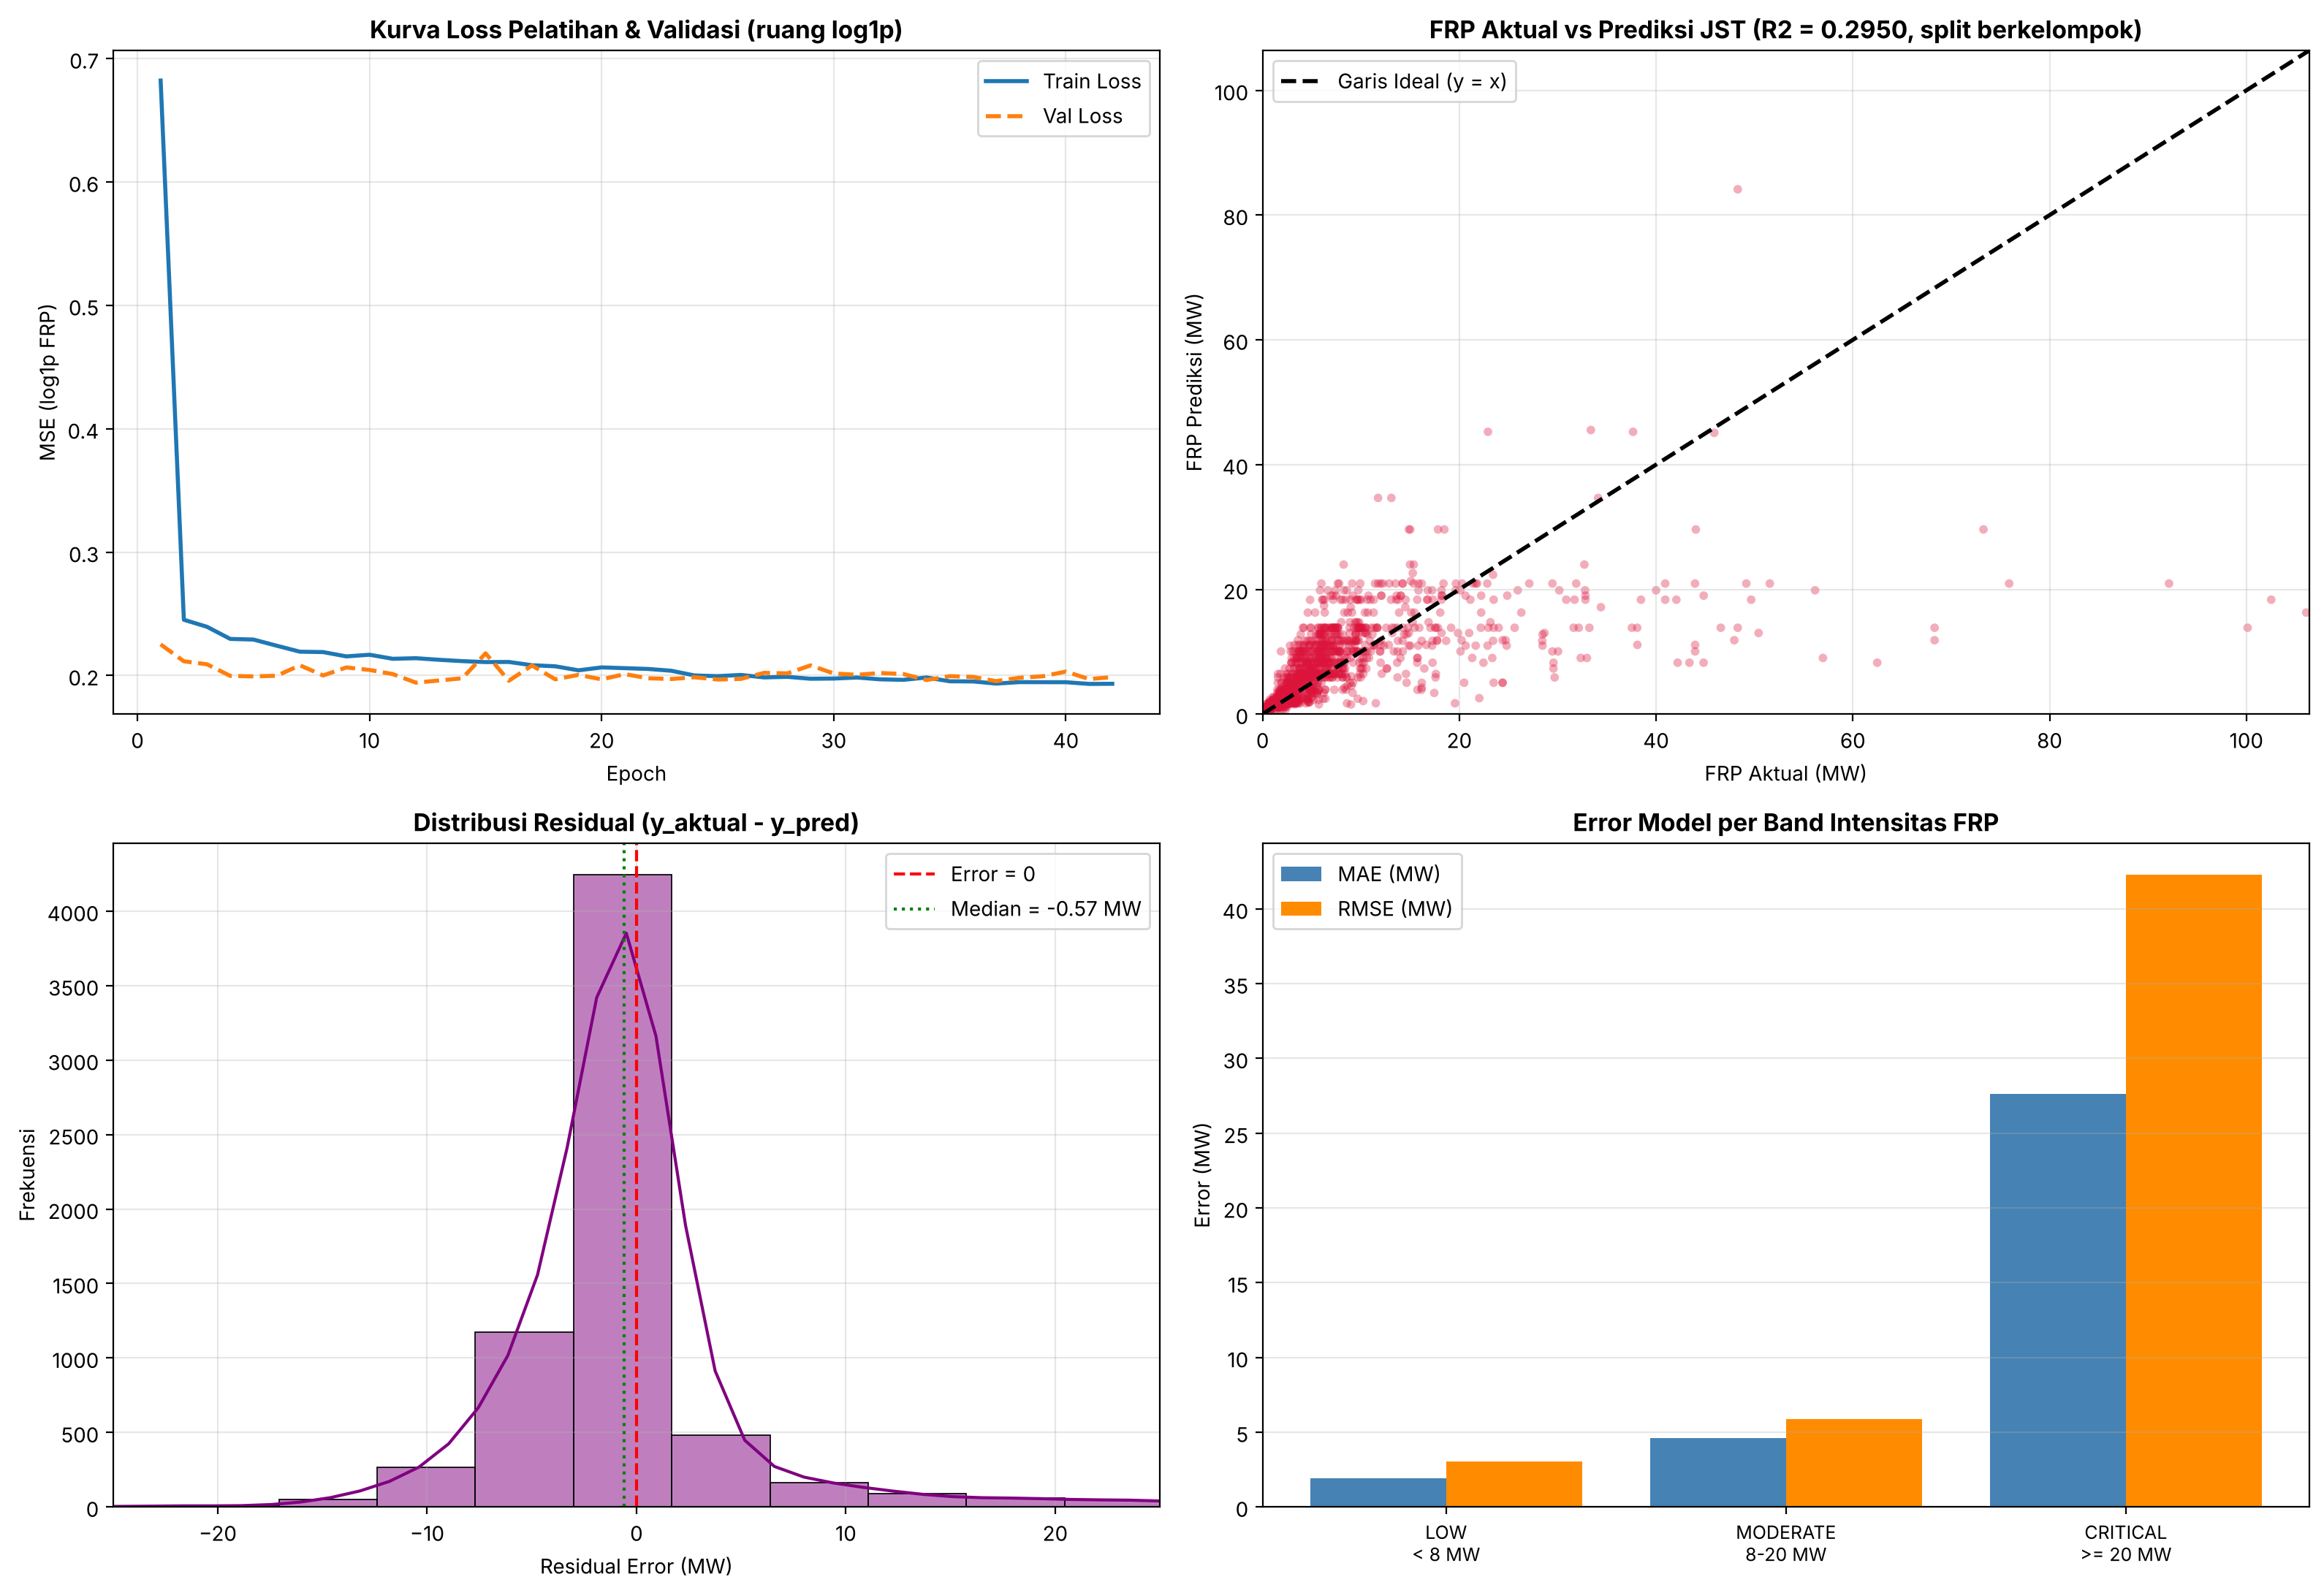

Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

ax = axes[0, 0]
ax.plot(range(1, epochs_run + 1), history['train_loss'], label='Train Loss', color='tab:blue', lw=2)
ax.plot(range(1, epochs_run + 1), history['val_loss'], label='Val Loss', color='tab:orange', lw=2, linestyle='--')
ax.set_title('Kurva Loss Pelatihan & Validasi (ruang log1p)', fontweight='bold')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (log1p FRP)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[0, 1]
subset = np.random.RandomState(SEED).choice(len(y_test), size=min(1500, len(y_test)), replace=False)
ax.scatter(y_test[subset], y_pred_cal[subset], alpha=0.35, color='crimson', edgecolors='none', s=18)
lim = max(np.percentile(y_test[subset], 99.5), np.percentile(y_pred_cal[subset], 99.5)) * 1.05
ax.plot([0, lim], [0, lim], '--k', lw=2, label='Garis Ideal (y = x)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_title(f'FRP Aktual vs Prediksi JST (R2 = {r2:.4f}, split berkelompok)', fontweight='bold')
ax.set_xlabel('FRP Aktual (MW)'); ax.set_ylabel('FRP Prediksi (MW)')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 0]
residuals = y_test - y_pred_cal
sns.histplot(residuals, bins=60, kde=True, color='purple', ax=ax)
ax.axvline(0, color='red', linestyle='--', label='Error = 0')
ax.axvline(np.median(residuals), color='green', linestyle=':',
           label=f'Median = {np.median(residuals):.2f} MW')
ax.set_xlim(-25, 25)
ax.set_title('Distribusi Residual (y_aktual - y_pred)', fontweight='bold')
ax.set_xlabel('Residual Error (MW)'); ax.set_ylabel('Frekuensi')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1, 1]
bands = [('LOW\n< 8 MW', y_test < 8),
         ('MODERATE\n8-20 MW', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL\n>= 20 MW', y_test >= 20)]
x_pos = np.arange(len(bands))
maes = [mean_absolute_error(y_test[m], y_pred_cal[m]) for _, m in bands]
rmses = [np.sqrt(mean_squared_error(y_test[m], y_pred_cal[m])) for _, m in bands]
ax.bar(x_pos - 0.2, maes, 0.4, label='MAE (MW)', color='steelblue')
ax.bar(x_pos + 0.2, rmses, 0.4, label='RMSE (MW)', color='darkorange')
ax.set_xticks(x_pos); ax.set_xticklabels([b for b, _ in bands], fontsize=9)
ax.set_title('Error Model per Band Intensitas FRP', fontweight='bold')
ax.set_ylabel('Error (MW)'); ax.legend(); ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('hasil_evaluasi_jst.png', dpi=300, bbox_inches='tight')
plt.show()
print('Grafik evaluasi disimpan ke: hasil_evaluasi_jst.png')

### 8b. Benchmark XGBoost & Ensemble

Data tabular sering lebih akurat dengan *gradient boosting*. Pipeline identik (fitur dan split berkelompok yang sama) dilatih dengan XGBoost `reg:tweedie` (varians 1,5) — asumsi yang cocok untuk FRP non-negatif dan sangat menceng.

Bobot ensemble dan model final dipilih **pada data validasi** (bukan test), sehingga angka uji tetap jujur.

In [13]:
def add_row(rows, name, p):
    rows.append({'Model': name, **regression_metrics(y_test, p)})

final_rows = []
add_row(final_rows, 'JST + kalibrasi isotonic', y_pred_cal)

# Kandidat model final dinilai pada VALIDASI, bukan test: (MSE val, fungsi prediksi, prediksi test, prediksi val)
candidates = {
    'JST + kalibrasi isotonic': (
        mse_of(y_val, y_pred_val_cal),
        lambda Z: np.clip(iso.predict(predict_jst(Z)), 0, None),
        y_pred_cal, y_pred_val_cal,
    )
}

try:
    import xgboost as xgb

    XGB_PARAMS = dict(objective='reg:tweedie', tweedie_variance_power=1.5,
                      n_estimators=4000, learning_rate=0.03, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8, min_child_weight=2, reg_lambda=1.0,
                      early_stopping_rounds=100, random_state=SEED, tree_method='hist',
                      device='cuda' if torch.cuda.is_available() else 'cpu')
    xgb_model = xgb.XGBRegressor(**XGB_PARAMS)
    xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

    y_pred_xgb = np.clip(xgb_model.predict(X_test), 0, None)
    y_pred_xgb_val = np.clip(xgb_model.predict(X_val), 0, None)
    add_row(final_rows, 'XGBoost (tweedie)', y_pred_xgb)

    # Ensemble: bobot dipilih pada validasi
    best_w, best_ens_val = 0.5, float('inf')
    for w in np.arange(0, 1.001, 0.05):
        v = mse_of(y_val, np.clip(w * y_pred_val_cal + (1 - w) * y_pred_xgb_val, 0, None))
        if v < best_ens_val:
            best_ens_val, best_w = v, w

    ens_name = f'Ensemble JST {best_w:.2f} + XGB {1 - best_w:.2f}'
    y_pred_ens = np.clip(best_w * y_pred_cal + (1 - best_w) * y_pred_xgb, 0, None)
    y_pred_ens_val = np.clip(best_w * y_pred_val_cal + (1 - best_w) * y_pred_xgb_val, 0, None)
    add_row(final_rows, ens_name, y_pred_ens)

    def _ens_predict(Z):
        jst_part = np.clip(iso.predict(predict_jst(Z)), 0, None)
        return np.clip(best_w * jst_part + (1 - best_w) * np.clip(xgb_model.predict(Z), 0, None), 0, None)

    candidates[ens_name] = (best_ens_val, _ens_predict, y_pred_ens, y_pred_ens_val)
except ImportError:
    xgb = None
    print('xgboost tidak terpasang, benchmark dilewati.')

best_name = min(candidates, key=lambda k: candidates[k][0])
best_val_mse, predict_final, y_pred_final, y_pred_final_val = candidates[best_name]

bench_df = pd.DataFrame(final_rows).sort_values('MSE')
print(f'Model final terpilih (MSE validasi terkecil = {best_val_mse:.4f}): {best_name}')
print('BENCHMARK MODEL (data uji berkelompok):')
display(bench_df.round(4))

Model final terpilih (MSE validasi terkecil = 53.8561): Ensemble JST 0.65 + XGB 0.35
BENCHMARK MODEL (data uji berkelompok):


,Model,MSE,RMSE,MAE,R2
2,Ensemble JST 0.65 + XGB 0.35,130.3743,11.4182,4.0514,0.3094
1,XGBoost (tweedie),130.4463,11.4213,4.0506,0.3091
0,JST + kalibrasi isotonic,133.0956,11.5367,4.1241,0.2950


In [14]:
# Evaluasi per-band untuk MODEL FINAL terpilih
bands = [('LOW (< 8 MW)', y_test < 8),
         ('MODERATE (8-20 MW)', (y_test >= 8) & (y_test < 20)),
         ('CRITICAL (>= 20 MW)', y_test >= 20)]

rows = []
for label, mask in bands:
    rows.append({'Band FRP': label, 'n Sampel': int(mask.sum()),
                 'Proporsi': f'{mask.mean() * 100:.1f}%',
                 'MAE (MW)': round(mean_absolute_error(y_test[mask], y_pred_final[mask]), 3),
                 'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test[mask], y_pred_final[mask])), 3),
                 'Bias (MW)': round(np.mean(y_pred_final[mask] - y_test[mask]), 3)})
rows.append({'Band FRP': 'SELURUH TEST', 'n Sampel': len(y_test), 'Proporsi': '100.0%',
             'MAE (MW)': round(mean_absolute_error(y_test, y_pred_final), 3),
             'RMSE (MW)': round(np.sqrt(mean_squared_error(y_test, y_pred_final)), 3),
             'Bias (MW)': round(np.mean(y_pred_final - y_test), 3)})
band_df = pd.DataFrame(rows)
print(f'PERFORMA MODEL FINAL ({best_name}) PER-BAND:')
display(band_df)

PERFORMA MODEL FINAL (Ensemble JST 0.65 + XGB 0.35) PER-BAND:


,Band FRP,n Sampel,Proporsi,MAE (MW),RMSE (MW),Bias (MW)
0,LOW (< 8 MW),5111,76.0%,1.906,3.055,1.516
1,MODERATE (8-20 MW),1166,17.3%,4.453,5.592,0.543
2,CRITICAL (>= 20 MW),452,6.7%,27.278,41.889,-26.197
3,SELURUH TEST,6729,100.0%,4.051,11.418,-0.514


#### Ambang alarm CRITICAL dituning di data validasi

Prediksi regresi cenderung tertarik ke tengah, sehingga ambang 20 MW jarang terlewati dan banyak titik api CRITICAL lolos. Untuk keputusan mitigasi, yang penting adalah **recall CRITICAL** (titik api berbahaya tidak terlewat). Ambang alarm dipilih pada **data validasi** sebagai ambang terbesar yang masih memberi recall ≥ 70%, lalu diuji jujur pada data uji. Definisi kelas aktual tetap: CRITICAL = FRP ≥ 20 MW.

In [15]:
MODERATE_MW, CRITICAL_MW, TARGET_RECALL = 8.0, 20.0, 0.70

def crit_stats(y_true, p, thr):
    true_c, pred_c = y_true >= CRITICAL_MW, p >= thr
    tp = (true_c & pred_c).sum()
    return {'Recall CRITICAL': tp / max(true_c.sum(), 1),
            'Presisi CRITICAL': tp / max(pred_c.sum(), 1),
            'Porsi titik ditandai CRITICAL': pred_c.mean()}

def status(v, crit_thr=CRITICAL_MW):
    return np.where(v >= crit_thr, 2, np.where(v >= MODERATE_MW, 1, 0))

# ambang terbesar yang masih memberi recall >= TARGET_RECALL di VALIDASI
p_crit_val = np.sort(y_pred_final_val[y_val >= CRITICAL_MW])[::-1]
k = int(np.ceil(TARGET_RECALL * len(p_crit_val)))
CRITICAL_ALERT_MW = float(max(p_crit_val[k - 1], MODERATE_MW))

rows = []
for rule, thr in [('Ambang tetap 20 MW', CRITICAL_MW),
                  (f'Ambang alarm dituning di validasi ({CRITICAL_ALERT_MW:.2f} MW)', CRITICAL_ALERT_MW)]:
    acc = (status(y_test) == status(y_pred_final, thr)).mean()
    rows.append({'Aturan': rule, **crit_stats(y_test, y_pred_final, thr), 'Akurasi 3 kelas': acc})
print(f'Model final: {best_name}')
display(pd.DataFrame(rows).round(4))

labels = ['LOW', 'MODERATE', 'CRITICAL']
cm = confusion_matrix(status(y_test), status(y_pred_final, CRITICAL_ALERT_MW), labels=[0, 1, 2])
print(f'Confusion matrix data uji (ambang alarm {CRITICAL_ALERT_MW:.2f} MW):')
display(pd.DataFrame(cm, index=[f'Aktual {l}' for l in labels], columns=[f'Prediksi {l}' for l in labels]))

Model final: Ensemble JST 0.65 + XGB 0.35


,Aturan,Recall CRITICAL,Presisi CRITICAL,Porsi titik ditandai CRITICAL,Akurasi 3 kelas
0,Ambang tetap 20 MW,0.2279,0.5365,0.0285,0.7570
1,Ambang alarm dituning di validasi (13.04 MW),0.6394,0.2905,0.1479,0.7233


Confusion matrix data uji (ambang alarm 13.04 MW):


,Prediksi LOW,Prediksi MODERATE,Prediksi CRITICAL
Aktual LOW,4155,743,213
Aktual MODERATE,250,423,493
Aktual CRITICAL,38,125,289


### 8c. Uji Ketahanan: Seberapa Besar Skor Dipengaruhi Cara Split?

Tiga pengecekan:
1. **Bukti kebocoran**: persentase titik uji yang tetangga terdekatnya di data latih (overpass yang sama) memiliki FRP **identik**, untuk split acak vs split berkelompok.
2. **Validasi silang XGBoost** (cepat) dengan tiga skema: KFold acak (bocor), GroupKFold per overpass × sel, dan *forward-chaining* per hari (latih hanya dengan hari-hari sebelumnya, uji hari berikutnya).
3. **Uji waktu untuk JST**: latih hari 0–9, validasi hari 10–11, uji hari 12–14.

In [16]:
overpass_arr = df_fe['overpass'].values
coords_rad = np.radians(df_fe[['latitude', 'longitude']].values)

def share_identical_neighbour(idx_tr, idx_te):
    hits = []
    for ov in np.unique(overpass_arr[idx_te]):
        tr = idx_tr[overpass_arr[idx_tr] == ov]
        te = idx_te[overpass_arr[idx_te] == ov]
        if len(tr) == 0:
            hits.append(np.zeros(len(te), dtype=bool))
            continue
        _, j = BallTree(coords_rad[tr], metric='haversine').query(coords_rad[te], k=1)
        hits.append(y[tr][j[:, 0]] == y[te])
    return np.concatenate(hits).mean()

idx_rand_tr, idx_rand_te = train_test_split(idx_all, test_size=0.2, random_state=SEED)
print(f'Titik uji dengan tetangga latih ber-FRP identik | split acak      : '
      f'{share_identical_neighbour(idx_rand_tr, idx_rand_te) * 100:.1f}%')
print(f'Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: '
      f'{share_identical_neighbour(idx_train_full, idx_test) * 100:.1f}%')

Titik uji dengan tetangga latih ber-FRP identik | split acak      : 29.6%


Titik uji dengan tetangga latih ber-FRP identik | split berkelompok: 0.4%


In [17]:
day_arr = df_fe['day_idx'].values

def robust_row(name, y_true, p):
    return {'Skema evaluasi': name, **regression_metrics(y_true, p),
            'R2 (skala log)': r2_score(np.log1p(y_true), np.log1p(p)),
            'Recall CRITICAL (20 MW)': crit_stats(y_true, p, CRITICAL_MW)['Recall CRITICAL']}

if xgb is not None:
    def fit_xgb_idx(tr, va):
        m = xgb.XGBRegressor(**XGB_PARAMS)
        m.fit(X[tr], y[tr], eval_set=[(X[va], y[va])], verbose=False)
        return m

    robust_rows = []
    oof = np.zeros(len(y))
    for tr, te in KFold(n_splits=5, shuffle=True, random_state=SEED).split(X):
        tr2, va = train_test_split(tr, test_size=0.2, random_state=SEED)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('KFold acak 5-fold (bocor)', y, oof))

    oof = np.zeros(len(y))
    for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
        tr2, va = grouped_split(tr, test_size=0.2)
        oof[te] = np.clip(fit_xgb_idx(tr2, va).predict(X[te]), 0, None)
    robust_rows.append(robust_row('GroupKFold 5-fold (overpass x sel 0,5°)', y, oof))

    y_fc, p_fc = [], []
    for day in range(6, day_arr.max() + 1):
        tr, va, te = (np.where(day_arr < day - 1)[0], np.where(day_arr == day - 1)[0],
                      np.where(day_arr == day)[0])
        if len(te) == 0 or len(va) == 0:
            continue
        y_fc.append(y[te])
        p_fc.append(np.clip(fit_xgb_idx(tr, va).predict(X[te]), 0, None))
    robust_rows.append(robust_row('Forward-chaining per hari (uji hari 6–14)',
                                  np.concatenate(y_fc), np.concatenate(p_fc)))
    print('VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:')
    display(pd.DataFrame(robust_rows).round(4))

VALIDASI SILANG XGBOOST — skor gabungan out-of-fold:


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (skala log),Recall CRITICAL (20 MW)
0,KFold acak 5-fold (bocor),73.4505,8.5703,3.1514,0.5188,0.7575,0.4645
1,"GroupKFold 5-fold (overpass x sel 0,5°)",92.8495,9.6358,3.6431,0.3917,0.6877,0.3453
2,Forward-chaining per hari (uji hari 6–14),85.4613,9.2445,3.5030,0.3494,0.6626,0.1704


In [18]:
# Uji waktu untuk JST: latih hari 0-9, validasi hari 10-11, uji hari 12-14
t_tr = np.where(day_arr <= 9)[0]
t_va = np.where((day_arr >= 10) & (day_arr <= 11))[0]
t_te = np.where(day_arr >= 12)[0]

scaler_t = StandardScaler().fit(X[t_tr])
net_t, _ = train_jst(scaler_t.transform(X[t_tr]), y[t_tr], scaler_t.transform(X[t_va]), y[t_va], verbose=False)
cap_t = np.log1p(y[t_tr].max())
p_va_t = jst_predict(net_t, scaler_t.transform(X[t_va]), cap_t)
p_te_t = jst_predict(net_t, scaler_t.transform(X[t_te]), cap_t)
iso_t = IsotonicRegression(out_of_bounds='clip').fit(p_va_t, y[t_va])

temporal_rows = [robust_row('JST + isotonic (uji hari 12–14)', y[t_te], np.clip(iso_t.predict(p_te_t), 0, None))]
if xgb is not None:
    temporal_rows.append(robust_row('XGBoost (uji hari 12–14)', y[t_te],
                                    np.clip(fit_xgb_idx(t_tr, t_va).predict(X[t_te]), 0, None)))
print(f'UJI WAKTU: latih {len(t_tr):,} | validasi {len(t_va):,} | uji {len(t_te):,} sampel')
display(pd.DataFrame(temporal_rows).round(4))

UJI WAKTU: latih 32,992 | validasi 1,077 | uji 1,757 sampel


,Skema evaluasi,MSE,RMSE,MAE,R2,R2 (skala log),Recall CRITICAL (20 MW)
0,JST + isotonic (uji hari 12–14),46.6774,6.8321,3.1173,0.3657,0.6496,0.1240
1,XGBoost (uji hari 12–14),46.4619,6.8163,3.2899,0.3687,0.6393,0.2231


### 9. Simulasi Inferensi: Estimasi Keganasan Titik Api Baru untuk Mitigasi Lapangan

Titik api baru diperlakukan seperti deteksi pada **overpass terakhir** (siang atau malam sesuai `is_day`): fitur termal dan temporal dibentuk dengan fungsi yang sama seperti saat pelatihan, dan kerapatan hotspot dihitung ulang bersama seluruh deteksi overpass tersebut. `acq_time` FIRMS dalam **UTC**; S-NPP melintasi Kalimantan sekitar 04–07 UTC (siang, ±11–14 WIB) dan 16–19 UTC (malam, ±23–02 WIB), jadi contoh di bawah memakai jam overpass yang realistis.

Kategori memakai **ambang alarm CRITICAL hasil tuning** pada data validasi.

In [19]:
sample_hotspots = pd.DataFrame([
    {'lokasi': 'Katingan (Hutan Gambut Pekat)', 'latitude': -2.05, 'longitude': 113.35, 'bright_ti4': 365.2, 'scan': 0.40, 'track': 0.38, 'bright_ti5': 304.5, 'is_day': 1, 'confidence_score': 3, 'acq_time': 605},
    {'lokasi': 'Seruyan (Dekat Pemukiman)', 'latitude': -2.52, 'longitude': 112.21, 'bright_ti4': 342.1, 'scan': 0.48, 'track': 0.42, 'bright_ti5': 298.0, 'is_day': 1, 'confidence_score': 2, 'acq_time': 625},
    {'lokasi': 'Ketapang (Titik Api Malam Hari)', 'latitude': -1.82, 'longitude': 110.15, 'bright_ti4': 324.6, 'scan': 0.55, 'track': 0.45, 'bright_ti5': 291.3, 'is_day': 0, 'confidence_score': 1, 'acq_time': 1750}
])

last_overpass = {flag: sorted(o for o in df_fe['overpass'].unique() if o.endswith('_' + flag))[-1]
                 for flag in ('D', 'N')}
sample_hotspots['overpass'] = np.where(sample_hotspots['is_day'] == 1, last_overpass['D'], last_overpass['N'])

sim = add_temporal_features(add_thermal_features(fix_i4(sample_hotspots))).reset_index(drop=True)
pool = pd.concat([df_fe[['overpass', 'latitude', 'longitude']],
                  sim[['overpass', 'latitude', 'longitude']]], ignore_index=True)
sim = pd.concat([sim, add_density_features(sim, build_density_tables(pool))], axis=1)

X_sim = sim[FEATURES].values.astype(np.float32)
pred_frp = predict_final(X_sim)
sample_hotspots['Prediksi FRP (MW)'] = np.round(pred_frp, 2)

def kategori_bahaya(frp_val):
    if frp_val >= CRITICAL_ALERT_MW:
        return 'CRITICAL / TINGGI (Prioritaskan Water Bombing Helikopter)'
    elif frp_val >= MODERATE_MW:
        return 'MODERATE / SEDANG (Tim Manggala Agni Darat)'
    else:
        return 'LOW / RINGAN (Pemantauan Satelit Berkala)'

sample_hotspots['Status & Rekomendasi Mitigasi'] = sample_hotspots['Prediksi FRP (MW)'].apply(kategori_bahaya)
print(f'Model: {best_name} | ambang alarm CRITICAL: {CRITICAL_ALERT_MW:.2f} MW')
display(sample_hotspots[['lokasi', 'latitude', 'longitude', 'bright_ti4', 'acq_time', 'overpass',
                         'Prediksi FRP (MW)', 'Status & Rekomendasi Mitigasi']])

Model: Ensemble JST 0.65 + XGB 0.35 | ambang alarm CRITICAL: 13.04 MW


,lokasi,latitude,longitude,bright_ti4,acq_time,overpass,Prediksi FRP (MW),Status & Rekomendasi Mitigasi
0,Katingan (Hutan Gambut Pekat),-2.05,113.35,365.2,605,2026-11-01_D,32.15,CRITICAL / TINGGI (Prioritaskan Water Bombing ...
1,Seruyan (Dekat Pemukiman),-2.52,112.21,342.1,625,2026-11-01_D,10.52,MODERATE / SEDANG (Tim Manggala Agni Darat)
2,Ketapang (Titik Api Malam Hari),-1.82,110.15,324.6,1750,2026-11-01_N,7.11,LOW / RINGAN (Pemantauan Satelit Berkala)


### 10. Kesimpulan

1. **Evaluasi tanpa kebocoran mengubah gambaran performa.** Pada split berkelompok, model final (ensemble JST 0,65 + XGB 0,35) mencapai R² 0,309 (MSE 130,37; MAE 4,05 MW); JST sendiri R² 0,295. Validasi silang XGBoost memberi R² 0,39 (GroupKFold) dan 0,35 (*forward-chaining*), dibandingkan 0,52 bila split acak. Selisih ini berasal dari piksel kembar yang bocor, bukan kemampuan model.
2. **Model tetap berguna untuk mengurutkan titik api**: R² skala log 0,69 (GroupKFold) dan median error absolut JST 1,39 MW. Kelemahannya ada pada nilai ekstrem: kelas CRITICAL memiliki bias −26,2 MW.
3. **Untuk keputusan mitigasi, ambang alarm 13,04 MW** (dituning di validasi) menaikkan recall CRITICAL dari 22,8% menjadi 63,9% pada data uji, dengan presisi 29,0% dan 14,8% titik ditandai. Sekitar 7 dari 10 alarm ternyata bukan CRITICAL; kompromi ini wajar bila melewatkan api besar jauh lebih mahal daripada alarm palsu.
4. **Piksel I4 terlipat dan jenuh kini ditangani**: prediksi mentah tertinggi tidak lagi melampaui FRP maksimum data latih (319,5 MW), dan kalibrasi isotonic tinggal mengoreksi bias `expm1` (MSE validasi 59,63 → 54,88).
5. Pada uji waktu, JST dan XGBoost setara (R² 0,366 vs 0,369), tetapi recall CRITICAL pada ambang 20 MW sangat rendah (12–22%): untuk hari-hari baru, prediksi makin tertarik ke tengah.

**Batasan yang tersisa** (butuh data baru, bukan tuning):
- FRP produk 375 m dihitung dari kanal M13 (750 m) yang tidak ada di CSV FIRMS, dan 3,3% piksel I4 jenuh pada 367 K; fitur piksel tunggal tidak bisa membedakan intensitas di atas saturasi.
- Hanya 15 hari pada satu musim dan satu satelit (S-NPP).
- Belum ada data cuaca, gambut/tutupan lahan, atau riwayat FRP dari overpass sebelumnya.

**Arah pengembangan**: tambahkan deteksi NOAA-20/NOAA-21 (lebih banyak overpass per hari dan riwayat per lokasi), data cuaca (mis. ERA5), peta gambut, serta periode lebih panjang. Evaluasi selalu dengan skema berkelompok atau berurutan waktu.